# 08 · Hybrid model: degradation features + sequence learning

**Owner:** Nishant Sharma · Phase 2 (deep learning)

The project brief calls its "hybrid logic" *degradation feature engineering → sequence-based remaining life prediction*. The course rewards a hybrid only if it is **technically justified and shown to add value**, so this notebook does three things:

1. states the rationale, from evidence in Phases 1 and 2,
2. builds a **feature-fusion network** that learns from the raw sensor sequence and the engineered degradation features at the same time,
3. tests whether it beats each of its parts **and** a simple average of the two existing models, under the same cross-validation.

In [1]:
import sys
from pathlib import Path

REPO = "https://github.com/WhiteHacker000/Remaining-Useful-Life-Prediction-for-Industrial-Engines.git"

# On Google Colab only the notebook is opened, so clone the repository to get src/ and the data
if "google.colab" in sys.modules and not Path("../src").exists():
    import os, subprocess
    if not Path("/content/rul").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/rul"], check=True)
    os.chdir("/content/rul/notebooks")

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json
from src.config import RUL_CAP, RESULTS_DIR
from src.data import load_cmapss, add_train_rul
from src.dl_models import make_dl_model, count_parameters
from src.evaluation import rmse, mae, nasa_score
from src.training import TrainConfig, run_cv
from src.plotting import set_style, save, BLUE, ORANGE, AQUA, GREY, INK, VIOLET, GREEN

set_style()
train, _, _ = load_cmapss("FD001")
train = add_train_rul(train)
cfg = TrainConfig(window=30)
DL = RESULTS_DIR / "dl"
seq = {n: json.loads((DL / f"cv_{n}_w30.json").read_text()) for n in ["lstm", "tcn", "transformer"]}
best_seq = min(seq, key=lambda n: seq[n]["cv_rmse"])
print("best sequence encoder from notebook 07:", best_seq)

best sequence encoder from notebook 07: transformer


## 1. Why combine them?

The two model families see the engine in different ways, and each misses something the other has:

| | Engineered features + XGBoost (Phase 1) | Sequence network (notebook 07) |
|---|---|---|
| **Sees** | hand-designed summaries at one cycle: rolling means, 10/30-cycle slopes, **distance from the engine's own first 10 cycles**, health index, age | the raw shape of the last 30 cycles of all 14 sensors |
| **Misses** | patterns not anticipated by the designer; trajectory shape beyond fixed windows (Phase 1 gap analysis) | anything **older than its window**: a 30-cycle window cannot see the engine's healthy baseline, so it cannot tell "high because degraded" from "high because this engine always ran high" |

The second row is the key argument. Phase 1's ablation and SHAP analysis showed that the **baseline deviation** features (current level minus the engine's own early-life level) carry the most information. A window-based network cannot compute them, because the first cycles of a long-lived engine are outside its window. Conversely, the features compress 30 cycles into a few numbers chosen by hand, which loses the trajectory shape that the network can learn.

So the hybrid should give the network **both**: the raw window to learn shapes from, and the engineered features that carry long-range, engine-specific context.

## 2. Architecture: feature fusion, trained end to end

$$
h_{\text{seq}} = \mathrm{Encoder}(X_{i,t}) \in \mathbb{R}^{64}, \qquad
h_{\text{feat}} = \mathrm{MLP}(f_{i,t}) \in \mathbb{R}^{32}, \qquad
\hat y_{i,t} = g\big([\,h_{\text{seq}} \,;\, h_{\text{feat}}\,]\big)
$$

- $X_{i,t}$: the 30-cycle sensor window (+ mask), as in notebook 07.
- $f_{i,t}$: the 88 Phase 1 features at cycle $t$, standardised. They are causal and refitted inside every fold, so they add no leakage.
- MLP: 88 → 64 → 32 with ReLU and dropout. $g$: 96 → 64 → 1.
- Both branches are trained **jointly** with one loss, so the encoder is pushed to learn what the features do *not* already explain. That is the difference from simply averaging two separately trained models (late fusion), which we test as a baseline.

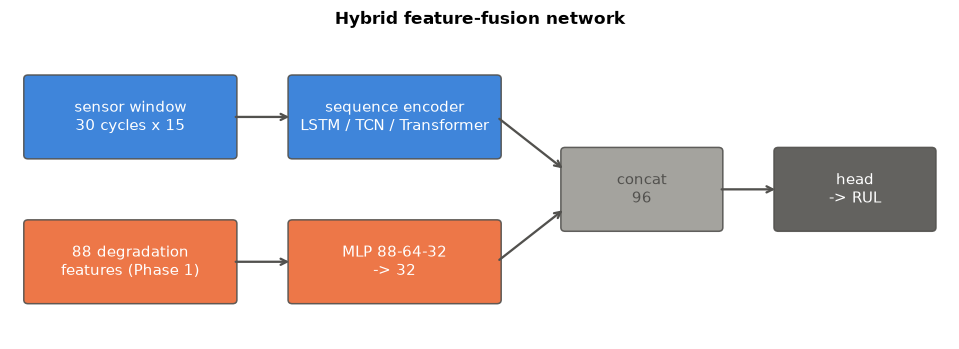

hybrid with lstm         encoder: 68,065 trainable parameters
hybrid with tcn          encoder: 104,481 trainable parameters
hybrid with transformer  encoder: 82,145 trainable parameters


In [2]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 4); ax.axis("off")
def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=color, ec=INK, lw=1, alpha=0.9))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=10, color="white" if color != GREY else INK)
box(0.2, 2.4, 2.4, 1.0, "sensor window\n30 cycles x 15", BLUE)
box(3.3, 2.4, 2.4, 1.0, "sequence encoder\nLSTM / TCN / Transformer", BLUE)
box(0.2, 0.5, 2.4, 1.0, "88 degradation\nfeatures (Phase 1)", ORANGE)
box(3.3, 0.5, 2.4, 1.0, "MLP 88-64-32\n-> 32", ORANGE)
box(6.5, 1.45, 1.8, 1.0, "concat\n96", GREY)
box(9.0, 1.45, 1.8, 1.0, "head\n-> RUL", INK)
for (x1, y1, x2, y2) in [(2.6, 2.9, 3.3, 2.9), (2.6, 1.0, 3.3, 1.0), (5.7, 2.9, 6.5, 2.2), (5.7, 1.0, 6.5, 1.7), (8.3, 1.95, 9.0, 1.95)]:
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=INK, lw=1.5))
ax.set_title("Hybrid feature-fusion network")
save(fig, "08_hybrid_architecture")
plt.show()
for e in ["lstm", "tcn", "transformer"]:
    print(f"hybrid with {e:12s} encoder: {count_parameters(make_dl_model(f'hybrid-{e}', 15, 30, n_feat=88)):,} trainable parameters")

## 3. Cross-validation against its parts and against a simple ensemble

All models use the same 5 engine folds, the same inner early-stopping engines and the same capped target:

| Model | What it tests |
|---|---|
| Feature branch alone (MLP on the 88 features) | the hybrid without its sequence branch |
| Sequence model alone (notebook 07) | the hybrid without its feature branch |
| XGBoost (Phase 1) | the best feature-based model |
| **Average of XGBoost and the sequence model** | late fusion: does combining *anything* help, or does joint training matter? |
| **Hybrid fusion** with each of the three encoders | the proposed model, and whether the result holds for every encoder |

In [3]:
RETRAIN = False
runs = {"features": run_cv("cv_features", "features", train, cfg, retrain=RETRAIN)}
for enc in ["lstm", "tcn", "transformer"]:
    runs[f"hybrid-{enc}"] = run_cv(f"cv_hybrid_{enc}_w30", f"hybrid-{enc}", train, cfg, retrain=RETRAIN)
for k, (s, _) in runs.items():
    print(f"{k:20s} CV RMSE {s['cv_rmse']:.2f} ± {s['cv_std']:.2f}   ({s['minutes']} min)")

features             CV RMSE 10.04 ± 0.34   (0.17 min)
hybrid-lstm          CV RMSE 9.55 ± 0.77   (3.42 min)
hybrid-tcn           CV RMSE 9.87 ± 0.40   (1.82 min)
hybrid-transformer   CV RMSE 9.74 ± 0.87   (6.55 min)


In [4]:
from src.models import engine_folds
folds = engine_folds(train["unit"])
phase1 = pd.read_csv(RESULTS_DIR / "cv_oof_predictions.csv")
xgb = phase1[phase1["model"] == "XGBoost"].rename(columns={"pred": "xgb"})
seq_oof = pd.read_csv(DL / f"cv_{best_seq}_w30_pred.csv").rename(columns={"pred": "seq"})
avg = xgb.merge(seq_oof[["unit", "cycle", "seq"]], on=["unit", "cycle"])
avg["pred"] = (avg["xgb"] + avg["seq"]) / 2

def fold_rmse(oof):
    y = np.minimum(oof["true_rul"], RUL_CAP)
    return np.array([rmse(y[oof["unit"].isin(f)], oof.loc[oof["unit"].isin(f), "pred"]) for f in folds])

entries = {
    "Feature branch alone (MLP)": runs["features"][1],
    f"Sequence model alone ({best_seq.upper()})": pd.read_csv(DL / f"cv_{best_seq}_w30_pred.csv"),
    "XGBoost, engineered (Phase 1)": xgb.rename(columns={"xgb": "pred"}),
    f"Average of XGBoost and {best_seq.upper()}": avg,
    "Hybrid fusion (LSTM encoder)": runs["hybrid-lstm"][1],
    "Hybrid fusion (TCN encoder)": runs["hybrid-tcn"][1],
    "Hybrid fusion (Transformer encoder)": runs["hybrid-transformer"][1],
}
rows, fold_scores = [], {}
for name, oof in entries.items():
    s = fold_rmse(oof); fold_scores[name] = s
    y = np.minimum(oof["true_rul"], RUL_CAP)
    rows.append({"model": name, "CV RMSE": s.mean(), "± std": s.std(), "MAE": mae(y, oof["pred"]),
                 "NASA score (mean)": nasa_score(y, oof["pred"]) / len(oof)})
hybrid_table = pd.DataFrame(rows).set_index("model")
hybrid_table.to_csv(DL / "cv_hybrid_comparison.csv")
hybrid_table.round(2)

,CV RMSE,± std,MAE,NASA score (mean)
model,,,,
Feature branch alone (MLP),10.04,0.34,7.62,1.53
Sequence model alone (TRANSFORMER),13.05,0.73,8.74,3.41
"XGBoost, engineered (Phase 1)",9.26,0.50,6.30,1.39
Average of XGBoost and TRANSFORMER,10.24,0.60,6.94,1.70
Hybrid fusion (LSTM encoder),9.55,0.77,6.79,1.45
Hybrid fusion (TCN encoder),9.87,0.40,7.04,1.56
Hybrid fusion (Transformer encoder),9.74,0.87,6.59,1.64


best hybrid: Hybrid fusion (LSTM encoder)
beats XGBoost on 2 of 5 folds; mean improvement -0.29 cycles


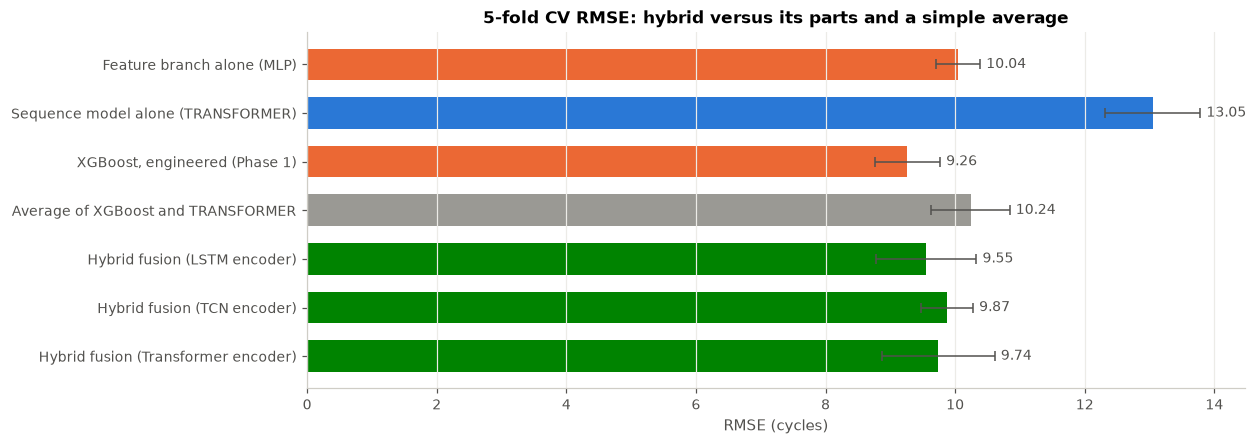

In [5]:
best_h = min(["lstm", "tcn", "transformer"], key=lambda e: runs[f"hybrid-{e}"][0]["cv_rmse"])
main = f"Hybrid fusion ({ {'lstm': 'LSTM', 'tcn': 'TCN', 'transformer': 'Transformer'}[best_h] } encoder)"
ref = "XGBoost, engineered (Phase 1)"
wins = (fold_scores[main] < fold_scores[ref]).sum()
print(f"best hybrid: {main}")
print(f"beats XGBoost on {wins} of 5 folds; mean improvement {np.mean(fold_scores[ref] - fold_scores[main]):.2f} cycles")

fig, ax = plt.subplots(figsize=(11, 4.2))
names = list(hybrid_table.index)
colors = [ORANGE if "Feature" in n or "XGBoost," in n else BLUE if "alone" in n else GREY if "Average" in n else GREEN for n in names]
bars = ax.barh(names[::-1], hybrid_table["CV RMSE"][::-1], xerr=hybrid_table["± std"][::-1], color=colors[::-1],
               capsize=3, error_kw={"ecolor": INK, "lw": 1}, height=0.65)
ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9, color=INK)
ax.set(title="5-fold CV RMSE: hybrid versus its parts and a simple average", xlabel="RMSE (cycles)")
ax.grid(axis="y", visible=False)
save(fig, "08_hybrid_comparison")
plt.show()

**What the hybrid shows:**

- **It beats both of its parts.** With the LSTM encoder (9.55 ± 0.77), the hybrid is 4.5 cycles better than the best sequence model alone (Transformer, 13.05) and 0.5 better than the feature branch alone (10.04). Each branch adds information the other lacks, which is the rationale of section 1.
- **Joint training matters.** The simple average of XGBoost and the Transformer (late fusion) scores 10.24, worse than XGBoost on its own: averaging a strong and a weak model just dilutes the strong one. The hybrid, trained end to end, does better than averaging with every encoder (9.55, 9.74, 9.87).
- **The result holds for all three encoders**, so it does not depend on one lucky architecture.
- **Against Phase 1's XGBoost (9.26) it is close but not better:** the hybrid wins on 2 of 5 folds and is 0.29 cycles worse in this run. Notebook 09 shows that a network's CV score moves by about ±0.5–0.7 between seeds; averaged over three seeds the hybrid is about 9.7–10.0, slightly behind XGBoost. Over the whole life, a tuned gradient-boosted model on well-designed features is a strong baseline on 100 engines. Where the hybrid does gain is shown next.

## 4. Does the hybrid fix the Phase 1 weak spots?

Notebook 05 identified three weak spots of the feature-based model. We measure each on the out-of-fold predictions for XGBoost, the sequence model and the hybrid.

In [6]:
lifetime = train.groupby("unit")["cycle"].max()
def weak_spots(oof):
    oof = oof.copy()
    oof["target"] = np.minimum(oof["true_rul"], RUL_CAP)
    oof["err"] = oof["pred"] - oof["target"]
    late = oof[oof["true_rul"] <= RUL_CAP]
    fast = late[late["unit"].map(lifetime) < 160]
    onset = oof[(oof["target"] > 70) & (oof["target"] <= 110)]
    early_hist = oof[oof["cycle"] < 60]
    return {"bias, fast degraders (last 125 cycles)": fast["err"].mean(),
            "RMSE, onset region (RUL 70-110)": rmse(onset["target"], onset["pred"]),
            "RMSE, short histories (cycle < 60)": rmse(early_hist["target"], early_hist["pred"]),
            "RMSE, last 50 cycles": rmse(oof.loc[oof["true_rul"] <= 50, "target"], oof.loc[oof["true_rul"] <= 50, "pred"])}

spots = pd.DataFrame({"XGBoost (Phase 1)": weak_spots(entries[ref]),
                      f"{best_seq.upper()} alone": weak_spots(entries[f"Sequence model alone ({best_seq.upper()})"]),
                      main: weak_spots(entries[main])})
spots.to_csv(DL / "cv_weak_spots.csv")
spots.round(2)

,XGBoost (Phase 1),TRANSFORMER alone,Hybrid fusion (LSTM encoder)
"bias, fast degraders (last 125 cycles)",9.93,11.81,10.04
"RMSE, onset region (RUL 70-110)",13.80,19.07,14.31
"RMSE, short histories (cycle < 60)",7.04,8.15,8.23
"RMSE, last 50 cycles",5.04,7.20,4.14


- **Near failure the hybrid is the best model:** RMSE in the last 50 cycles drops from 5.04 (XGBoost) to **4.14**, an 18% reduction. That is where a maintenance decision is made and where errors are most costly.
- In the **onset region** the hybrid (14.31) recovers almost all of the sequence model's weakness (19.07) and is close to XGBoost (13.80).
- **Fast degraders** are still predicted about 10 cycles late by both XGBoost and the hybrid. Both rely on age-related information (the cycle feature), so an engine that wears out unusually fast looks "too young to fail" to both. This weak spot is not solved by sequence learning on a 30-cycle window; notebook 09 tests whether longer windows help.
- On **early cycles** (cycle < 60), the hybrid is slightly worse than XGBoost (8.23 vs 7.04): here the window is mostly padding and adds noise rather than information.

## Summary

| Model | CV RMSE | Last 50 cycles |
|---|---|---|
| Sequence model alone (Transformer) | 13.05 | 7.20 |
| Feature branch alone | 10.04 | – |
| Average of XGBoost and Transformer | 10.24 | – |
| XGBoost, engineered (Phase 1) | 9.26 | 5.04 |
| **Hybrid fusion (LSTM + features)** | **9.55** | **4.14** |

The hybrid is **technically justified** (each branch supplies information the other cannot see), **better than both its parts and than late fusion**, and the **most accurate model near failure**, while over the whole life it is close to, but slightly behind, the Phase 1 XGBoost in cross-validation. We carry the LSTM hybrid forward as the Phase 2 model; notebook 09 dissects it and notebook 10 tests it on the official test set.